# Spaghetti Chart vs. Highlight

**Family:** Bad vs. good &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Bad vs. good:* Common chart mistakes, each shown next to a better alternative that fixes it.

## Design purpose

Plotting a dozen or more colored lines together produces a "spaghetti" tangle. Colors run out and repeat, the legend becomes a lookup puzzle, and no single story stands out. The reader cannot follow any one line.

## When to use

- Highlight the one or two series that carry the message and gray the rest as context
- Use small multiples when every series matters equally

## Avoid when

- More than ~4–5 series on one line chart, each with its own color
- Default color cycles that repeat hues after 8–10 series

## Alternatives

- Highlight one series, gray the rest (with direct labels)
- Small multiples with the other series as a gray background
- Interactive chart with hover-to-highlight

## Design tips

- Decide what the reader should notice, then make only that colorful
- Label the highlighted lines at their end; drop the legend
- Put the message in the title ("Region 7 diverged after 2020")

## Example

Hospital readmission rate (%) for 12 regions, 2014–2024.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(8)
years = np.arange(2014, 2025)
series = {}
for i in range(12):
    base = rng.uniform(13, 17) + np.cumsum(rng.normal(0, 0.35, len(years)))
    series[f"Region {i + 1}"] = base
series["Region 7"] = 16 - 0.55 * (years - 2014) + rng.normal(0, 0.2, len(years))
df = pd.DataFrame(series, index=years)
df.round(1).head()

,Region 1,Region 2,Region 3,Region 4,Region 5,Region 6,Region 7,Region 8,Region 9,Region 10,Region 11,Region 12
2014,13.8,14.3,13.0,14.5,14.7,13.8,15.8,17.1,14.7,15.1,15.7,14.6
2015,13.4,14.0,12.9,13.7,14.3,14.1,15.5,17.1,14.4,14.8,15.3,14.6
2016,13.2,14.3,13.0,13.2,14.4,14.0,14.6,16.8,14.2,14.8,15.4,14.8
2017,12.4,14.2,12.4,13.7,14.0,14.7,14.2,16.9,14.6,15.0,15.5,14.8
2018,12.4,14.7,12.9,13.4,13.6,14.5,13.5,16.7,14.0,14.5,15.8,15.0


### Plot

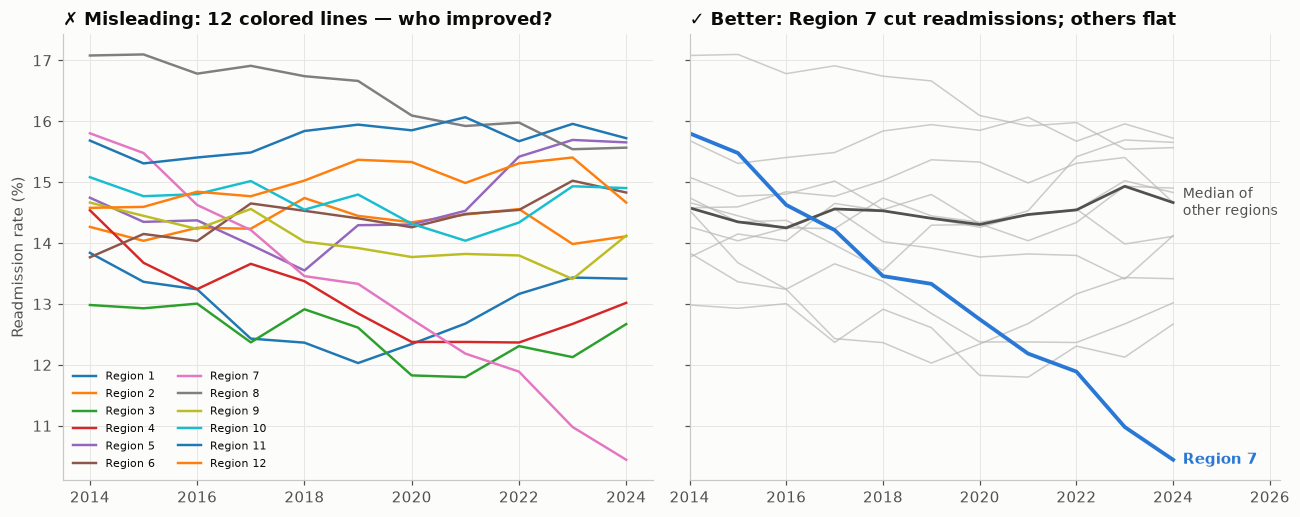

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)

# Misleading: 12 colors, a legend, no focus.
cmap = plt.get_cmap("tab10")
for i, col in enumerate(df.columns):
    ax1.plot(df.index, df[col], color=cmap(i % 10), linewidth=1.6, label=col)
ax1.legend(ncol=2, fontsize=7.5, loc="lower left")
ax1.set_ylabel("Readmission rate (%)")
ax1.set_title("✗ Misleading: 12 colored lines — who improved?", fontsize=11.5)

# Better: gray context, one highlight, the median for reference, direct labels.
for col in df.columns:
    ax2.plot(df.index, df[col], color=GRAY, linewidth=1, alpha=0.7)
med = df.drop(columns="Region 7").median(axis=1)
ax2.plot(df.index, med, color="#52514e", linewidth=1.8)
ax2.plot(df.index, df["Region 7"], color=PALETTE[0], linewidth=2.5)
ax2.text(years[-1] + 0.2, df["Region 7"].iloc[-1], "Region 7", color=PALETTE[0],
         va="center", fontsize=10, fontweight="bold")
ax2.text(years[-1] + 0.2, med.iloc[-1], "Median of\nother regions", color="#52514e",
         va="center", fontsize=9)
ax2.set_xlim(years[0], years[-1] + 2.2)
ax2.set_title("✓ Better: Region 7 cut readmissions; others flat", fontsize=11.5)
fig.tight_layout()
plt.show()

## How to read it

On the left, try to find which region improved most. On the right, the same twelve lines are drawn, but the one improving region is highlighted, the typical region is shown as the median, and the rest recede.

---
Standalone script: [`spaghetti_vs_highlight.py`](spaghetti_vs_highlight.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)